In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define a simple sample "image" as a 2D NumPy array.
# This image has a distinct vertical edge down the middle.
input_image = np.array([
    [10, 10, 10, 0, 0, 0],
    [10, 10, 10, 0, 0, 0],
    [10, 10, 10, 0, 0, 0],
    [10, 10, 10, 0, 0, 0],
    [10, 10, 10, 0, 0, 0],
    [10, 10, 10, 0, 0, 0]
])

# 2. Define the kernel (or filter).
# This kernel is designed to detect vertical edges. It responds strongly
# where there's a transition from high values (left) to low values (right).
kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
])

print("--- Convolution Demo ---")
print("Original Image:\n", input_image)
print("\nVertical Edge Detection Kernel:\n", kernel)



--- Convolution Demo ---
Original Image:
 [[10 10 10  0  0  0]
 [10 10 10  0  0  0]
 [10 10 10  0  0  0]
 [10 10 10  0  0  0]
 [10 10 10  0  0  0]
 [10 10 10  0  0  0]]

Vertical Edge Detection Kernel:
 [[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]]


In [2]:
# --- The Core Convolution Operation-------

# Get dimensions of the image and the kernel
image_height, image_width = input_image.shape
kernel_height, kernel_width = kernel.shape

# Calculate the dimensions of the output feature map (no padding).
output_height = image_height - kernel_height + 1
output_width = image_width - kernel_width + 1

# Initialize the output feature map with zeros
feature_map = np.zeros((output_height, output_width))

# Slide the kernel over every possible location in the image
for y in range(output_height):
    for x in range(output_width):
        # Extract the current region of interest (ROI)
        roi = input_image[y:y + kernel_height, x:x + kernel_width]

        # Perform the dot product and store the result
        feature_map[y, x] = np.sum(roi * kernel)

# Print the resulting feature map
# Notice the high values where the vertical edge was detected.
print("\nResulting Feature Map:\n", feature_map)



Resulting Feature Map:
 [[ 0. 30. 30.  0.]
 [ 0. 30. 30.  0.]
 [ 0. 30. 30.  0.]
 [ 0. 30. 30.  0.]]


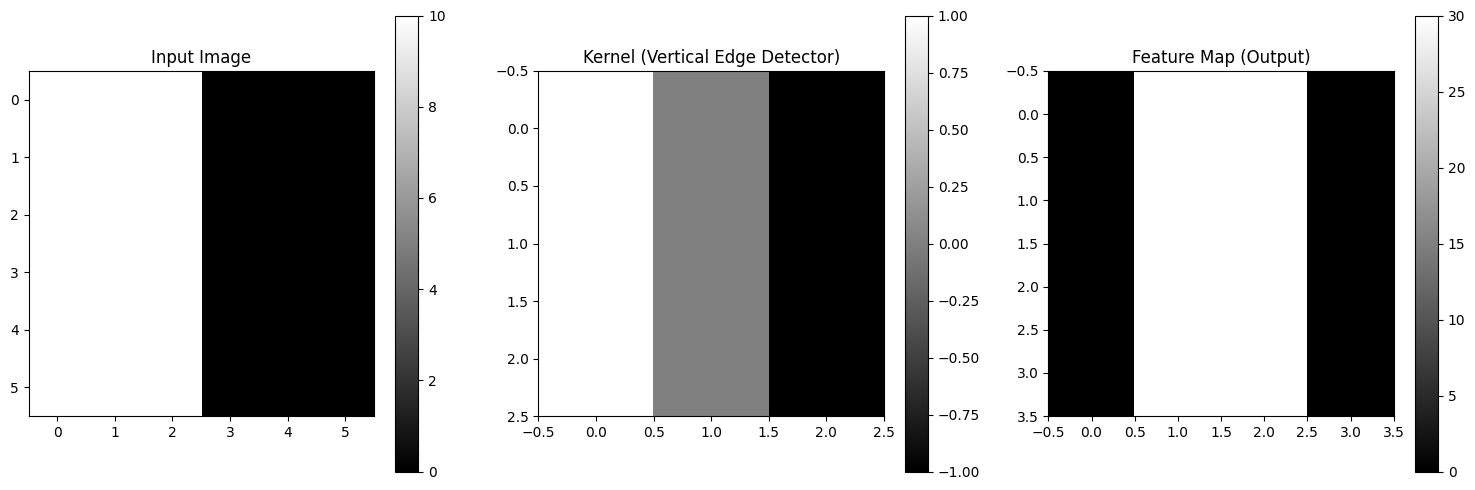

In [3]:

# --- Visualization ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot the Input Image
ax1 = axes[0]
im1 = ax1.imshow(input_image, cmap='gray')
ax1.set_title('Input Image')
fig.colorbar(im1, ax=ax1)

# Plot the Kernel
ax2 = axes[1]
im2 = ax2.imshow(kernel, cmap='gray')
ax2.set_title('Kernel (Vertical Edge Detector)')
fig.colorbar(im2, ax=ax2)

# Plot the Feature Map (Output)
ax3 = axes[2]
im3 = ax3.imshow(feature_map, cmap='gray')
ax3.set_title('Feature Map (Output)')
fig.colorbar(im3, ax=ax3)

plt.tight_layout()
plt.show()

